In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:6 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:10 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,412 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,550 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,17

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

main.cpp:3:10: fatal error: cuda_runtime.h: No such file or directory
    3 | #include <cuda_runtime.h>
      |          ^~~~~~~~~~~~~~~~
compilation terminated.
/bin/bash: line 1: ./app: No such file or directory


In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Ters DFT (IDFT) Hesaplama Fonksiyonu
def idft_hesapla(dft_shift_matrix):
    # fftshift işlemini geri alıyoruz
    f_ishift = np.fft.ifftshift(dft_shift_matrix)
    # Ters DFT uyguluyoruz
    img_back = np.fft.ifft2(f_ishift)
    # Gerçel kısmı alıp değer aralığını düzenliyoruz
    img_back = np.abs(img_back)
    return np.clip(img_back, 0, 255).astype(np.uint8)

# 2. Zero Mean Normalized Cross Correlation (ZMNCC) Hesaplama Fonksiyonu
def zmncc_hesapla(resim1, resim2):
    r1 = resim1.astype(np.float64)
    r2 = resim2.astype(np.float64)

    # Ortalama (Mean) değerlerini çıkarma (Zero Mean)
    r1_zero = r1 - np.mean(r1)
    r2_zero = r2 - np.mean(r2)

    # Pay ve Payda hesaplamaları
    pay = np.sum(r1_zero * r2_zero)
    payda = np.sqrt(np.sum(r1_zero ** 2) * np.sum(r2_zero ** 2))

    if payda == 0:
        return 0.0
    return pay / payda

Orijinal vs Geri Kazanılan Orijinal ZMNCC: 0.999981
Orijinal vs Geri Kazanılan Gauss Gürültülü ZMNCC: 0.912749
Orijinal vs Geri Kazanılan Salt&Pepper Gürültülü ZMNCC: 0.839878


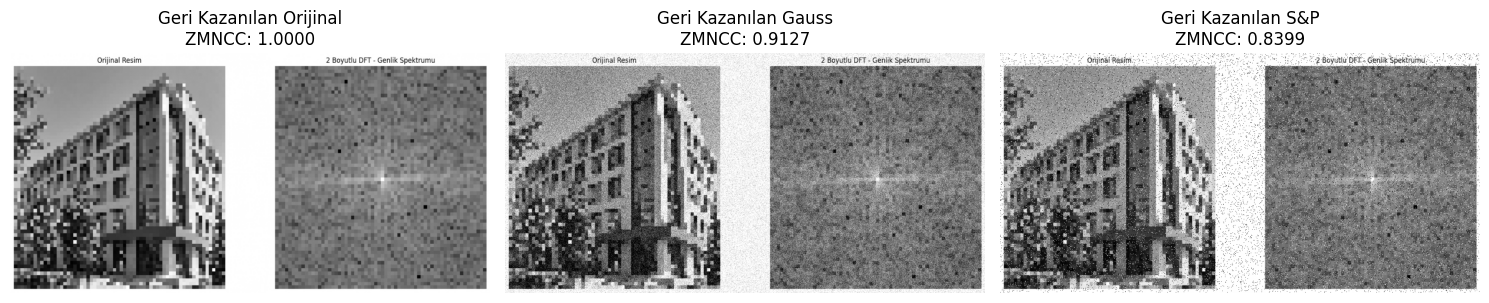

In [11]:
# Orijinal, Gauss ve Salt&Pepper görüntülerinin FFT matrisleri üzerinden ters işlem yapıyoruz
dft_orig_complex = np.fft.fftshift(np.fft.fft2(orijinal_resim))
dft_gauss_complex = np.fft.fftshift(np.fft.fft2(gauss_resim))
dft_sp_complex = np.fft.fftshift(np.fft.fft2(sp_resim))

# Ters DFT ile geri dönüştürülmüş görüntüler
rec_orijinal = idft_hesapla(dft_orig_complex)
rec_gauss = idft_hesapla(dft_gauss_complex)
rec_sp = idft_hesapla(dft_sp_complex)

# ZMNCC Skorlarının Hesaplanması
zmncc_orijinal = zmncc_hesapla(orijinal_resim, rec_orijinal)
zmncc_gauss = zmncc_hesapla(orijinal_resim, rec_gauss)
zmncc_sp = zmncc_hesapla(orijinal_resim, rec_sp)

print(f"Orijinal vs Geri Kazanılan Orijinal ZMNCC: {zmncc_orijinal:.6f}")
print(f"Orijinal vs Geri Kazanılan Gauss Gürültülü ZMNCC: {zmncc_gauss:.6f}")
print(f"Orijinal vs Geri Kazanılan Salt&Pepper Gürültülü ZMNCC: {zmncc_sp:.6f}")

# Görselleştirme
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(rec_orijinal, cmap='gray')
plt.title(f'Geri Kazanılan Orijinal\nZMNCC: {zmncc_orijinal:.4f}'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(rec_gauss, cmap='gray')
plt.title(f'Geri Kazanılan Gauss\nZMNCC: {zmncc_gauss:.4f}'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(rec_sp, cmap='gray')
plt.title(f'Geri Kazanılan S&P\nZMNCC: {zmncc_sp:.4f}'), plt.axis('off')
plt.tight_layout()
plt.show()

### Piksel Değerlerinin Yakınlığını Ölçen Diğer Metrikler ve Kıyaslama Raporu

İki görüntünün piksel bazlı veya yapısal benzerliğini değerlendirmek için kullanılan yaygın metrikler şunlardır:

#### 1. Mean Squared Error (MSE - Ortalama Karesel Hata)
* **Tanım:** İki görüntü arasındaki piksel farklarının karelerinin ortalamasıdır.
* **Avantajları:** Matematiksel olarak hesaplanması son derece kolaydır, optimizasyon problemlerinde türevlenebilir olduğu için sıklıkla tercih edilir.
* **Dezavantajları:** İnsan gözünün algısal hassasiyetine uymaz. Örneğin, hafif bir parlaklık kayması büyük bir MSE hatasına yol açarken insan gözü farkı hissetmeyebilir.

#### 2. Peak Signal-to-Noise Ratio (PSNR - Tepe Sinyal-Gürültü Oranı)
* **Tanım:** Sinyalin gücü ile parazit (gürültü) gücü arasındaki oranı logaritmik (dB) olarak verir.
* **Avantajları:** Sıkıştırma ve gürültü azaltma algoritmalarının başarısını ölçmek için endüstriyel bir standarttır.
* **Dezavantajları:** Tıpkı MSE gibi sadece piksel farklarına odaklanır; yapısal değişimleri, kontrastı veya insan gözünün seçiciliğini hesaba katmaz.

#### 3. Structural Similarity Index (SSIM - Yapısal Benzerlik İndeksi)
* **Tanım:** Görüntüleri parlaklık (luminance), kontrast (contrast) ve yapısal (structural) olmak üzere 3 farklı boyutta kıyaslar.
* **Avantajları:** İnsan görsel algı sistemiyle en yüksek korelasyona sahip metriktir. Görüntü kalitesi kayıplarını insan gözüne en yakın şekilde modeller.
* **Dezavantajları:** Hesaplama karmaşıklığı MSE ve PSNR'ye göre çok daha yüksektir.